## Inside the Black Box: From Metropolis-Hastings to Hamiltonian Monte Carlo for Bayesian Linear Regression

#### Anastasiia Khorkhorina
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering

### Subsurface Machine Learning Course, The University of Texas at Austin
#### Hildebrand Department of Petroleum and Geosystems Engineering, Cockrell School of Engineering
#### Department of Geological Sciences, Jackson School of Geosciences

_____________________

Workflow supervision and review by:

#### Instructor: Prof. Michael Pyrcz, Ph.D., P.Eng., Associate Professor, The Univeristy of Texas at Austin
[Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Geostatistics Book](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) | [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)  | [Applied Geostats in Python e-book](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)

#### Course TA: Alexander Ikenaike, Graduate Student, The University of Texas at Austin
##### [LinkedIn](https://www.linkedin.com/in/alexander-ifenaike/)



### Executive Summary

Bayesian methods give a full distribution of model parameters instead of one answer, but the posterior usually cannot be calculated directly, so it is sampled with Markov Chain Monte Carlo (MCMC), which libraries run in one line, leaving students with a "black box". To open this box, I built a Metropolis–Hastings (MH) sampler and a Hamiltonian Monte Carlo (HMC) sampler from scratch for Bayesian linear regression of gas production from porosity, visualized MH with trace plots and Manim animations, and compared both with NUTS, the industry-standard sampler in PyMC. MH recovered the Ordinary Least Squares slope (0.86) with its uncertainty (0.81–0.91), its step size controlled whether the chain explored efficiently or got stuck, and a wrong prior barely mattered with 200 wells but dominated with 10 (slope pulled from 0.86 to 0.42); HMC and NUTS gave the same answer with 3–7 times more effective samples, and on a synthetic correlated posterior MH was practically stuck while NUTS still sampled well. I recommend learning how such methods work from the basics, so that we understand what we use and why, instead of blindly trusting the output of a library or an AI tool.

### Import Packages

First, we load the packages used throughout the workflow:

* NumPy - used for arrays, random numbers, and all the math inside the samplers.
* pandas - used to load the data file and summarize it.
* matplotlib - used to plot the figures.
* SciPy (scipy.stats) - used to calculate the normal distribution's log-density, the building block of the likelihood and the prior.
* scikit-learn (LinearRegression) - used to fit the Ordinary Least Squares benchmark, which we compare the Bayesian results against.
* PyMC and ArviZ - PyMC is used to run NUTS (the sampler used in practice); ArviZ is used to check the results (effective sample size, r̂).
* Manim - used for animations.

The warnings suppression block is from Prof. Michael Pyrcz's course workflows ([GeostatsGuy GitHub](https://github.com/GeostatsGuy/PythonNumericalDemos)).

In [1]:
suppress_warnings = True

import numpy as np                                             # arrays and random numbers
import pandas as pd                                            # load and summarize the data
import matplotlib.pyplot as plt                                # plots
import scipy.stats as st                                       # normal distribution log-densities
from sklearn.linear_model import LinearRegression              # OLS benchmark
import pymc as pm                                              # NUTS sampler (industry-standard Bayesian library)
import arviz as az                                             # summaries and effective sample size
import logging                                                 
from manim import *                                            # animations

logging.getLogger('pytensor').setLevel(logging.ERROR)          # hide PyMC compiler messages
logging.getLogger('pymc').setLevel(logging.ERROR)              # hide PyMC sampling messages

if suppress_warnings == True:  
    import warnings                                            # suppress any warnings for this demonstration
    warnings.filterwarnings('ignore')

### Functions

Next, we define all the functions that will be used in the workflow:

In [2]:
def log_likelihood(beta, x, y):                          # Bayesian likelihood
    b1, b0, sigma = beta
    if sigma <= 0:
        return -np.inf
    y_pred = b1 * x + b0
    log_density = st.norm.logpdf(y, loc = y_pred, scale = sigma)
    return np.sum(log_density)

def log_prior(beta, b1_mean = 0, b1_sd = 1):             # Bayesian prior
    b1, b0, sigma = beta
    if sigma <= 0:
        return -np.inf
    lp_b1 = st.norm.logpdf(b1, loc = b1_mean, scale = b1_sd)
    lp_b0 = st.norm.logpdf(b0, loc = 0, scale = 1)
    return lp_b1 + lp_b0

def log_posterior(beta, x, y, b1_mean = 0, b1_sd = 1):   # Bayesian posterior
    lp = log_prior(beta, b1_mean, b1_sd)
    if lp == -np.inf:
        return -np.inf
    return lp + log_likelihood(beta, x, y)

def propose(beta, step):                                 # random-walk proposal around the current point
    return beta + np.random.normal(0, step, size = 3)

def metropolis(x, y, beta_start, step, n_iter, b1_mean = 0, b1_sd = 1):   # Metropolis-Hastings sampler, stores chain and proposals
    chain = np.zeros((n_iter, 3))                        # current state at each iteration
    proposals = np.zeros((n_iter, 3))                    # proposed state at each iteration
    accepted = np.zeros(n_iter, dtype = bool)            # True if proposal accepted
    beta = np.array(beta_start)
    lp_current = log_posterior(beta, x, y, b1_mean, b1_sd)
    for i in range(n_iter):
        beta_new = propose(beta, step)
        proposals[i] = beta_new
        lp_new = log_posterior(beta_new, x, y, b1_mean, b1_sd)
        log_alpha = lp_new - lp_current
        if np.log(np.random.rand()) < log_alpha:         # accept with probability min(1, ratio)
            beta = beta_new
            lp_current = lp_new
            accepted[i] = True
        chain[i] = beta
    return chain, accepted, proposals

def metropolis_1d(b1_start, step, n_iter, b0, sigma, x, y):   # 1D sampler for b1 only (b0, sigma fixed), (for the animation)
    current = np.zeros(n_iter)                           # b1 before each proposal
    proposal = np.zeros(n_iter)                          # proposed b1
    alpha = np.zeros(n_iter)                             # acceptance probability
    accepted = np.zeros(n_iter, dtype = bool)
    b1 = b1_start
    lp_current = log_posterior([b1, b0, sigma], x, y)
    for i in range(n_iter):
        current[i] = b1
        b1_new = b1 + np.random.normal(0, step)          # propose a new b1
        proposal[i] = b1_new
        lp_new = log_posterior([b1_new, b0, sigma], x, y)
        alpha[i] = np.exp(min(0, lp_new - lp_current))   # acceptance probability(0,1)
        if np.random.rand() < alpha[i]:
            b1 = b1_new
            lp_current = lp_new
            accepted[i] = True
    return current, proposal, alpha, accepted

def grad_log_posterior(beta, x, y, h = 1e-5):             # numerical gradient of the log-posterior
    grad = np.zeros(3)
    for k in range(3):
        e = np.zeros(3)
        e[k] = h                                         # nudge only parameter k
        grad[k] = (log_posterior(beta + e, x, y) - log_posterior(beta - e, x, y)) / (2 * h)
    return grad

def leapfrog(q, p, eps, L, x, y):                        # roll the ball for L steps of size eps
    q = q.copy(); p = p.copy()
    p = p + 0.5 * eps * grad_log_posterior(q, x, y)      # half kick
    for l in range(L):
        q = q + eps * p                                  # drift: position moves with velocity
        if l < L - 1:
            p = p + eps * grad_log_posterior(q, x, y)    # full kick
    p = p + 0.5 * eps * grad_log_posterior(q, x, y)      # final half kick
    return q, p

def energy(q, p, x, y):                                  # total energy = height (-log-posterior) + motion
    return -log_posterior(q, x, y) + 0.5 * np.sum(p**2)

def hmc(x, y, beta_start, eps, L, n_iter):               # Hamiltonian Monte Carlo sampler
    chain = np.zeros((n_iter, 3))
    accepted = np.zeros(n_iter, dtype = bool)
    q = np.array(beta_start, dtype = float)
    for i in range(n_iter):
        p0 = np.random.normal(size = 3)                  # 1. random kick
        q_new, p_new = leapfrog(q, p0, eps, L, x, y)     # 2. roll the ball
        if np.isfinite(log_posterior(q_new, x, y)):      # skip if the ball rolled to sigma <= 0
            if np.log(np.random.rand()) < energy(q, p0, x, y) - energy(q_new, p_new, x, y):   # 3. accept if energy (almost) conserved
                q = q_new
                accepted[i] = True
        chain[i] = q                                     # store current state (repeat if rejected)
    return chain, accepted

def autocorr(v, max_lag):                                # autocorrelation of a chain for lags 0..max_lag
    v = v - v.mean()
    return np.array([np.sum(v[:len(v) - k] * v[k:]) / np.sum(v * v) for k in range(max_lag + 1)])

def ess(samples):                                        # effective sample size of one parameter
    return float(az.ess(np.asarray(samples).reshape(1, -1)))

def nuts(x, y, seed):                                    # NUTS with PyMC, same model and priors as above
    with pm.Model():
        b1 = pm.Normal('b1', mu = 0, sigma = 1)          # prior for the slope
        b0 = pm.Normal('b0', mu = 0, sigma = 1)          # prior for the intercept
        sigma = pm.HalfFlat('sigma')                     # flat prior, sigma > 0 only
        pm.Normal('y', mu = b1 * x + b0, sigma = sigma, observed = y)   # likelihood
        return pm.sample(1000, tune = 1000, chains = 4, random_seed = seed, progressbar = False)

**Workflow settings:** random seed, features, and MCMC parameters:

In [3]:
seed = 73073                       # random seed
np.random.seed(seed)

xname = 'Por'; xlabel = 'Porosity, %'    # predictor feature and axis label with units
yname = 'Prod'; ylabel = 'Production, MCFPD'    # response feature and axis label with units

n_iter = 10000                     # number of MCMC iterations
step = 0.05                          # proposal step size (standardized units)
beta_start = [-1.5, 1.5, 2.0]        # starting point [b1, b0, sigma]
burn = 500                           # burn-in samples to discard

### Load Data

Now we read the data file and prepare it for modelling:

The data are 200 unconventional wells; we use one predictor (porosity) and one response (production), so the posterior can be visualized

Standardization - both features are rescaled to mean 0 and standard deviation 1:
$$z = \frac{x - \bar{x}}{s_x}$$

In Section 9, we see what happens if we don't standardize the data prior to the calculations.

Dataset: unconv_MV_v5.csv from Prof. Michael Pyrcz's [GeoDataSets](https://github.com/GeostatsGuy/GeoDataSets) GitHub repository.

* **Por** – porosity, fraction of rock void, %
* **Prod** – gas production rate, MCFPD

In [4]:
# os.chdir('/Users/...')                        # in case you want to read your file
# df = pd.read_csv('unconv_MV_v5.csv')

df = pd.read_csv('https://raw.githubusercontent.com/GeostatsGuy/GeoDataSets/master/unconv_MV_v5.csv')   # load data from Dr. Pyrcz's GeoDataSets GitHub repository

X = df[xname].values; Y = df[yname].values      # predictor and response arrays
df.head()                                       # preview the first rows

,Well,Por,Perm,AI,Brittle,TOC,VR,Prod
0,1,12.08,2.92,2.80,81.40,1.16,2.31,4165.196191
1,2,12.38,3.53,3.22,46.17,0.89,1.88,3561.146205
2,3,14.02,2.59,4.01,72.80,0.89,2.72,4284.348574
3,4,17.67,6.75,2.63,39.81,1.08,1.88,5098.680869
4,5,17.52,4.57,3.18,10.94,1.51,1.90,3406.132832


Summary statistics of the dataset.

In [5]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Well,200.0,100.500000,57.879185,1.000000,50.750000,100.500000,150.250000,200.000000
Por,200.0,14.991150,2.971176,6.550000,12.912500,15.070000,17.402500,23.550000
Perm,200.0,4.330750,1.731014,1.130000,3.122500,4.035000,5.287500,9.870000
AI,200.0,2.968850,0.566885,1.280000,2.547500,2.955000,3.345000,4.630000
Brittle,200.0,48.161950,14.129455,10.940000,37.755000,49.510000,58.262500,84.330000
TOC,200.0,0.990450,0.481588,-0.190000,0.617500,1.030000,1.350000,2.180000
VR,200.0,1.964300,0.300827,0.930000,1.770000,1.960000,2.142500,2.870000
Prod,200.0,4311.219852,992.038414,2107.139414,3618.064513,4284.687348,5086.089761,6662.622385


Truncate any negative values to zero.

In [6]:
df = df.clip(lower = 0)                                       # truncate negative values to 0
df.describe().transpose()                                     # summary statistics after truncation

,count,mean,std,min,25%,50%,75%,max
Well,200.0,100.500000,57.879185,1.000000,50.750000,100.500000,150.250000,200.000000
Por,200.0,14.991150,2.971176,6.550000,12.912500,15.070000,17.402500,23.550000
Perm,200.0,4.330750,1.731014,1.130000,3.122500,4.035000,5.287500,9.870000
AI,200.0,2.968850,0.566885,1.280000,2.547500,2.955000,3.345000,4.630000
Brittle,200.0,48.161950,14.129455,10.940000,37.755000,49.510000,58.262500,84.330000
TOC,200.0,0.991950,0.478264,0.000000,0.617500,1.030000,1.350000,2.180000
VR,200.0,1.964300,0.300827,0.930000,1.770000,1.960000,2.142500,2.870000
Prod,200.0,4311.219852,992.038414,2107.139414,3618.064513,4284.687348,5086.089761,6662.622385


Standardization:

In [7]:
x_mean = X.mean(); x_std = X.std()                  # porosity mean and standard deviation
y_mean = Y.mean(); y_std = Y.std()                  # production mean and standard deviation
sX = (X - x_mean)/x_std; sY = (Y - y_mean)/y_std    # standardized predictor and response

### Bayesian Linear Regression with MCMC

**Sections:**
1. Benchmark: Ordinary Least Squares
2. Bayesian model: likelihood, prior, posterior
3. Metropolis–Hastings sampler
4. Posterior results
5. Animations
6. Experiment: step size
7. Experiment: when does the prior matter?
8. Hamiltonian Monte Carlo and NUTS
9. Synthetic example: when Metropolis–Hastings gets stuck

### 1. Benchmark: Ordinary Least Squares

Before going Bayesian, we fit the classic linear regression, so we have a reference answer to compare with:

* the linear regression model, where $x$ is porosity, $y$ is production, $b_1$ is the slope, $b_0$ is the intercept, and $\epsilon$ is the error:
$$y = b_1 \cdot x + b_0 + \epsilon$$
* Ordinary Least Squares (OLS) finds the $b_1$ and $b_0$ that minimize the residual sum of squares (RSS), i.e., the squared differences between the data and the line:
$$RSS = \sum_{i=1}^{n} \left( y_i - (b_1 x_i + b_0) \right)^2$$
* because the error is squared (L2 norm), there is an analytical solution: no iterations, just one formula
* in standardized units, the OLS slope equals the correlation coefficient: $b_1 = r = 0.862$
* σ is estimated from the residuals (data minus prediction)
* the limitation - OLS gives one single line and says nothing about how certain it is; this is what the Bayesian approach adds.

In [8]:
ols = LinearRegression().fit(sX.reshape(-1, 1), sY)

b1_ols = ols.coef_[0]
b0_ols = ols.intercept_
sY_pred = ols.predict(sX.reshape(-1, 1))
sY_res = sY - sY_pred
std_ols = sY_res.std()

print('b1, slope = ', np.round(b1_ols, 3),
      'b0, intercept =', np.round(b0_ols, 3),
      'standard deviation =', np.round(std_ols, 3))

b1, slope =  0.862 b0, intercept = -0.0 standard deviation = 0.507


Data with the Ordinary Least Squares (OLS) line.

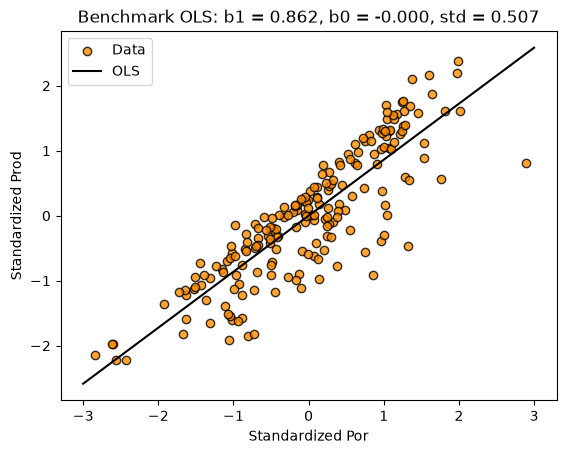

In [9]:
plt.scatter(sX, sY, color='darkorange', edgecolor='black', alpha=0.8, label='Data')

x_line = np.linspace(-3, 3, 100)                              # 100 evenly spaced x values from -3 to 3
y_line = b1_ols * x_line + b0_ols                             # the OLS equation applied to each
plt.plot(x_line, y_line, color='black', label='OLS')

plt.xlabel('Standardized ' + xname)
plt.ylabel('Standardized ' + yname)
plt.title(f'Benchmark OLS: b1 = {b1_ols:.3f}, b0 = {b0_ols:.3f}, std = {std_ols:.3f}')

plt.legend()
plt.grid(False)
plt.show()

### 2. Bayesian Model

Now we set up the Bayesian version of the same model; instead of one best line, we want to know how plausible every possible line is:

* Bayesian regression treats b1, b0 and σ as uncertain quantities with probability distributions, not as fixed numbers
Bayes' theorem:
$$P(\beta | \text{y, X}) = \frac{P(\text{y, X} | \beta)\, P(\beta)}{P(\text{y, X})}$$
* posterior P(β | y, X) - what we believe after seeing the data; this is the goal
* likelihood P(y, X | β) - how probable the observed data are if β were the true parameters
* prior P(β) - what we believe before the data
* evidence P(y, X) - a normalizing constant; it is an integral over all possible parameter values and usually impossible to calculate, and this is exactly why we need MCMC

Ordinary Least Squares (OLS) gives just one answer - one straight line.

Bayesian regression asks a different question: given the data, how plausible is each possible combination of (b₁, b₀, σ)? The answer is a distribution over parameters, the posterior, written P(β | data), where β = (b₁, b₀, σ). We estimate the model parameter distributions through Bayesian updating for inferring the model parameters from a prior and likelihood from training data.

#### Likelihood

The likelihood connects the model to the data, so we start with it:

* each well is assumed to scatter around the line with a normal error:
$$y_i \sim N(b_1 x_i + b_0,\ \sigma)$$
* the wells are independent, so the likelihood is the product over all wells, which in logs becomes a sum:
$$\log L = \sum_{i=1}^{n} \log N(y_i \mid b_1 x_i + b_0,\ \sigma)$$
* if the assumptions below are violated (e.g., skewed errors, changing scatter), the uncertainty will be misestimated

Assumptions:

1. Gaussian errors: scatter plot shows a skewed group of wells below the line, so this is only approximately true.
2. Independent wells: reasonable for different wells.
3. Constant σ, variance.

#### Prior

Then we decide what we believe before looking at the data:

b1, b0 ~ N(0, 1) - in standardized units this is weak: 
* a slope of 0.86 is entirely plausible, while a slope of 10 would be very surprising
* σ - flat for σ > 0: any positive value is equally plausible, and a negative σ is impossible (log-prior = -∞)

With 200 wells, the data dominate a weak prior.

#### Posterior

Finally, we combine the two into the posterior, the quantity every sampler explores:

* log-posterior = log-prior + log-likelihood
* why logs? If we multiplied the likelihoods of 200 wells, each a small number like 0.01, the result would be 10⁻⁴⁰⁰, which is too small for a computer to store, so it would turn into exactly 0 and every line would look equally bad. But if we take logs, the product becomes a sum of 200 ordinary numbers (each about -4.6), which a computer handles easily.
* why the evidence doesn't matter - MCMC only ever compares two points, and in the ratio posterior(new) / posterior(current) the evidence P(data) appears on top and on the bottom, so it cancels.

### 3. Metropolis–Hastings Sampler

We start far from the answer on purpose, β = (−1.5, 1.5, 2.0), to see if the chain finds the posterior by itself.

* Markov chain - each new sample depends only on the current one
* Monte Carlo - random sampling
* why the chain finds the posterior - uphill moves are always accepted, while downhill moves are accepted only sometimes, more often if they are only slightly lower; in the long run, the chain visits each region in proportion to its posterior probability, so a histogram of the chain is the posterior
* acceptance probability - for a symmetric proposal (a normal step is equally likely forwards and backwards, so the "Hastings" correction cancels):
$$\alpha = \min\left(1,\ \frac{P(\beta_{new} \mid \text{data})}{P(\beta \mid \text{data})}\right), \qquad \log\alpha = \text{log-post}(\beta_{new}) - \text{log-post}(\beta)$$

The Metropolis–Hastings algorithm, repeated for every iteration:

1. **Propose** a new point by a small random step from the current one: β_new = β + N(0, step)
2. **Compare** how plausible both points are: log α = log-posterior(β_new) - log-posterior(β)
3. **Accept** the proposal with probability α = min(1, posterior ratio):
    * uphill (better fit) → always accepted
    * downhill (worse fit) → sometimes accepted, which lets the chain explore the whole distribution
4. If rejected, **stay** and record the current point again (repeats are part of the sample)

In [10]:
np.random.seed(seed)
chain, accepted, proposals = metropolis(sX, sY, beta_start, step, n_iter)
print('Acceptance rate:', np.round(accepted.mean(), 3))

Acceptance rate: 0.268


### 4. Posterior Results

Next, we check whether the chain worked and summarize what it found:

* trace plot - the value of each parameter at every iteration:
   * at the start, the chain walks from the bad starting point to the posterior; this part is the burn-in, and we discard it
   * after that, a good chain looks like noise around a stable level ("fuzzy caterpillar"), with no trends and no long flat stretches
* P10, P50, P90 - the 10th, 50th and 90th percentiles of the samples:
   * P50 is the posterior median
   * P10-P90 is an 80% credible interval: "given the data and the prior, there is an 80% probability that b1 lies in this range"
* histograms - the shape of the posterior for each parameter; here they are symmetric and centered on OLS, as expected with a lot of data and weak priors

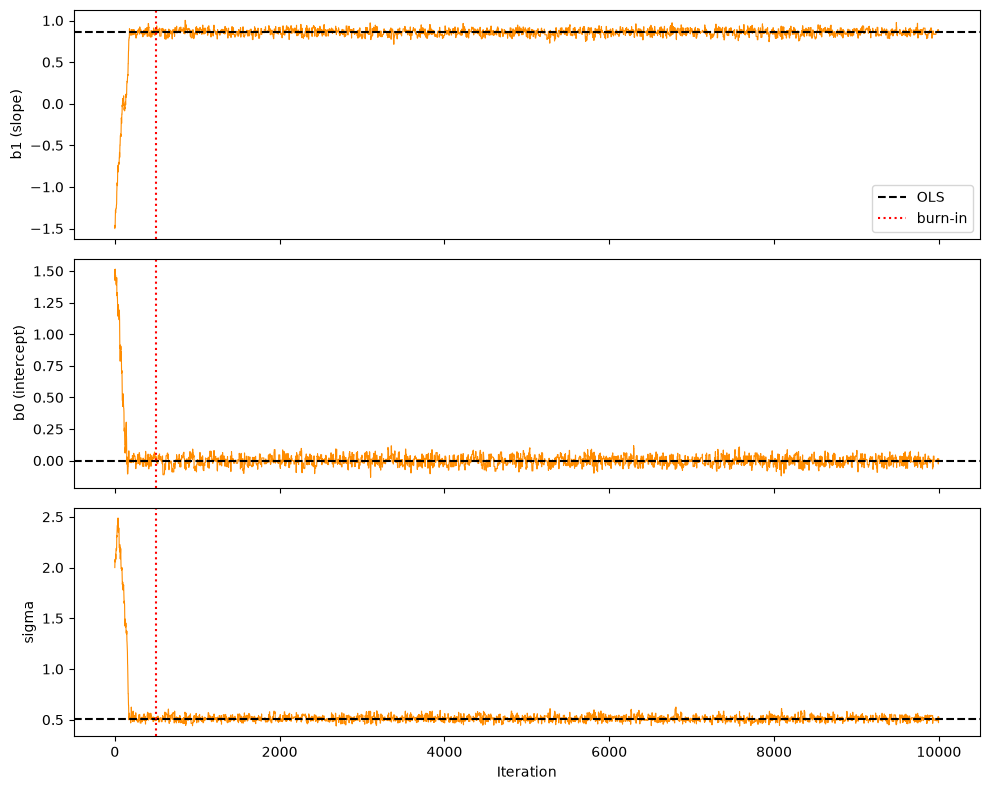

In [11]:
names = ['b1 (slope)', 'b0 (intercept)', 'sigma']
ols_values = [b1_ols, b0_ols, std_ols]                     # OLS values for comparison

fig, axes = plt.subplots(3, 1, figsize = (10, 8), sharex = True)
for k in range(3):
    axes[k].plot(chain[:, k], color = 'darkorange', lw = 0.8)              # k-th parameter, all iterations
    axes[k].axhline(ols_values[k], color = 'black', ls = '--', label = 'OLS')
    axes[k].axvline(burn, color = 'red', ls = ':', label = 'burn-in')      # end of burn-in
    axes[k].set_ylabel(names[k])
axes[0].legend()
axes[2].set_xlabel('Iteration')
plt.tight_layout(); plt.show()

Remove burn-in chain and summarize each parameter with P10, P50, P90:

In [12]:
post = chain[burn:]                                   

for k in range(3):
    p10, p50, p90 = np.percentile(post[:, k], [10, 50, 90])
    print(names[k], ': P10 =', np.round(p10, 3), ' P50 =', np.round(p50, 3), ' P90 =', np.round(p90, 3))

b1 (slope) : P10 = 0.813  P50 = 0.86  P90 = 0.907
b0 (intercept) : P10 = -0.046  P50 = -0.002  P90 = 0.045
sigma : P10 = 0.481  P50 = 0.511  P90 = 0.546


Posterior distributions compared with OLS.

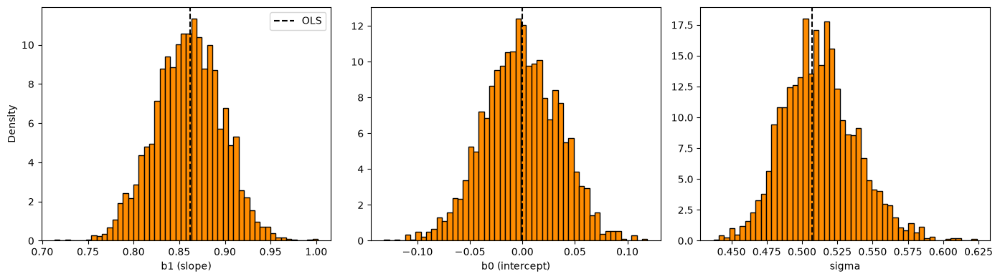

In [13]:
fig, axes = plt.subplots(1, 3, figsize = (14, 4))
for k in range(3):
    axes[k].hist(post[:, k], bins = 50, color = 'darkorange', edgecolor = 'black', density = True)
    axes[k].axvline(ols_values[k], color = 'black', ls = '--', label = 'OLS')
    axes[k].set_xlabel(names[k])
axes[0].set_ylabel('Density')
axes[0].legend()
plt.tight_layout(); plt.show()

#### Converting back to original units

Finally, we convert the results back to units that are meaningful for production:

* undo the standardization for every sample:

   * slope: $b_1 = b_{1,s} \cdot \frac{s_y}{s_x}$ (MCFPD per % porosity)
   * intercept: $b_0 = \bar{y} + s_y \cdot b_{0,s} - b_1 \cdot \bar{x}$
   * scatter: $\sigma = \sigma_s \cdot s_y$

* because every posterior sample is converted, the uncertainty is carried over as well
* the intercept is very uncertain (-232 to 249 MCFPD) because it is the production at porosity = 0, far outside the data (6.5-23.5 %), so a small change in slope swings it a lot

In [14]:
b1_o  = post[:, 0] * y_std / x_std                            
b0_o  = y_mean + y_std * post[:, 1] - b1_o * x_mean          
sig_o = post[:, 2] * y_std                                

for name, values in zip(['b1, MCFPD per %', 'b0, MCFPD', 'sigma, MCFPD'], [b1_o, b0_o, sig_o]):
    p10, p50, p90 = np.percentile(values, [10, 50, 90])
    print(name, ': P10 =', np.round(p10, 1), ' P50 =', np.round(p50, 1), ' P90 =', np.round(p90, 1))

b1, MCFPD per % : P10 = 271.4  P50 = 287.2  P90 = 302.9
b0, MCFPD : P10 = -232.3  P50 = 1.8  P90 = 249.4
sigma, MCFPD : P10 = 475.9  P50 = 505.6  P90 = 540.1


### 5. Animations

Now we watch the sampler at work, step by step:

* 2D chain walk - each point on the plane is one candidate line (b1, b0)
  
* 1D side view - only b1 moves (b0 and σ fixed at OLS), so the posterior can be drawn as a curve, a "hill":
   * proposals land on the curve, so we can see whether they are higher (always accepted, α = 1) or lower (accepted with probability α < 1)
   * the histogram below counts where the chain has been, repeats included; gradually it takes the shape of the curve, which means the samples reproduce the target distribution, the core idea of MCMC

Animations are built with [Manim Community](https://www.manim.community/) (v0.22.1); rendered GIFs are linked below each scene so they also play on GitHub.

2D chain walk - each point on the plane is one candidate line (b1, b0):
* yellow = proposal, green = accepted, red = rejected
* the gold trail is the burn-in: the chain walks from a terrible line (negative slope) to the OLS answer
* σ is not shown, but it changes too, and that is why the path bends: the chain fixes the intercept first, then the slope

Manim Community v0.22.1

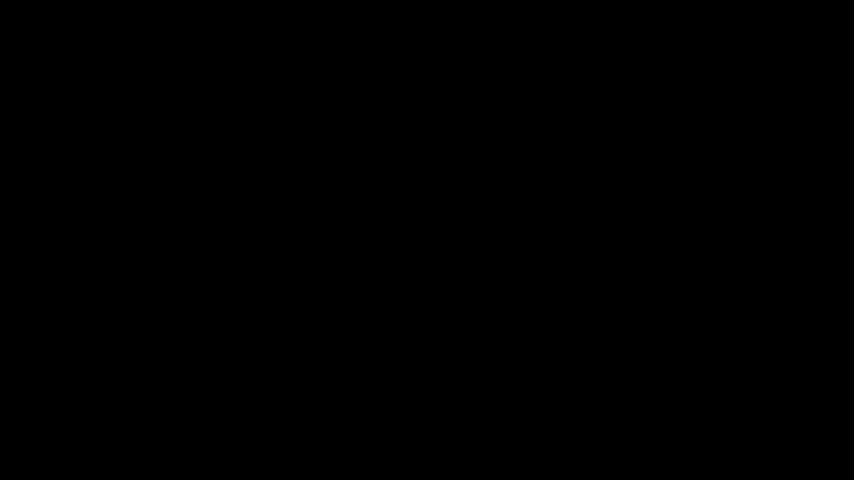

In [15]:
%%manim -ql -v WARNING --format=gif ChainWalk2D

class ChainWalk2D(Scene):
    def construct(self):
        axes = Axes(x_range = [-2, 2, 0.5], y_range = [-2, 2, 0.5],
                    x_length = 6, y_length = 6)
        x_lab = Text('b1 (slope)', font_size = 24).next_to(axes.x_axis, RIGHT)
        y_lab = Text('b0 (intercept)', font_size = 24).next_to(axes.y_axis, UP)
        self.play(Create(axes), FadeIn(x_lab), FadeIn(y_lab))

        target = Dot(axes.c2p(b1_ols, b0_ols), color = BLUE, radius = 0.12)                     # OLS answer
        t_lab = Text('OLS', font_size = 20).next_to(target, UR)
        self.play(FadeIn(target), FadeIn(t_lab))

        dot = Dot(axes.c2p(beta_start[0], beta_start[1]), color = GOLD)                         # starting point
        self.play(FadeIn(dot))


        n_show = 200                                              # how many iterations to animate
        current = axes.c2p(beta_start[0], beta_start[1])          # screen position of the chain now

        for i in range(n_show):
            prop_pt = axes.c2p(proposals[i, 0], proposals[i, 1])  
            line = Line(current, prop_pt, color = YELLOW, stroke_width = 2)
            prop = Dot(prop_pt, color = YELLOW, radius = 0.05)
            self.play(Create(line), FadeIn(prop), run_time = 0.08)

            if accepted[i] == True:                                                     # was proposal i accepted?
                self.play(prop.animate.set_color(GREEN), dot.animate.move_to(prop_pt), run_time = 0.08)
                self.add(Line(current, prop_pt, color = GOLD, stroke_width = 1.5))   # trail
                current = prop_pt                                           # the chain moved: update!
                self.remove(prop)
            else:
                self.play(prop.animate.set_color(RED), run_time = 0.08)
                self.play(FadeOut(prop), run_time = 0.07)
            self.remove(line)
            self.bring_to_front(dot)                                    # keep gold dot on top

![Chain walk in 2D](https://raw.githubusercontent.com/anastasiia57759/ML_Course_Project/main/animations/ChainWalk2D.gif)

Side view: only b1 moves (b0 and σ fixed at OLS), so the posterior can be drawn as a curve.

In [16]:
np.random.seed(seed)
cur1, prop1, alpha1, acc1 = metropolis_1d(0.70, 0.08, 300, b0_ols, std_ols, sX, sY)
print('Acceptance rate:', np.round(acc1.mean(), 3))

Acceptance rate: 0.45


Posterior height for any b1, scaled so the peak equals 1.

In [17]:
lp_peak = log_posterior([b1_ols, b0_ols, std_ols], sX, sY)          # log-posterior at the top of the hill

def hill(b1):                                                       # posterior height, scaled so the peak = 1
    return np.exp(log_posterior([b1, b0_ols, std_ols], sX, sY) - lp_peak)

The chain walks on the posterior curve. Below, the histogram of visited values builds up and matches the curve.

Manim Community v0.22.1

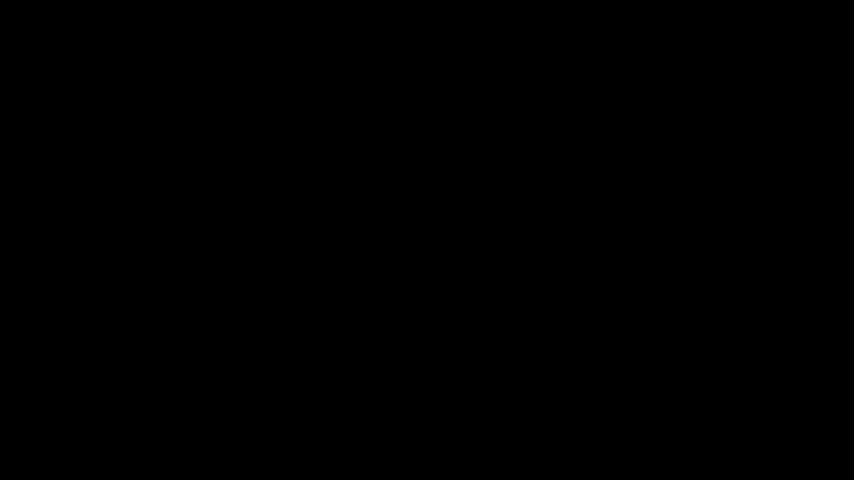

In [18]:
%%manim -ql -v WARNING --format=gif SideView1D

class SideView1D(Scene):
    def construct(self):
        axes = Axes(x_range = [0.65, 1.05, 0.05], y_range = [0, 1.2, 0.2],
                    x_length = 10, y_length = 4,
                    axis_config = {'include_tip': False}).shift(UP * 0.5)
        x_lab = Text('b1 (slope)', font_size = 22).next_to(axes.x_axis, RIGHT)
        y_lab = Text('posterior', font_size = 22).next_to(axes, LEFT)
        self.play(Create(axes), FadeIn(x_lab), FadeIn(y_lab))

        curve = axes.plot(hill, x_range = [0.65, 1.05], color = BLUE)     # posterior curve
        self.play(Create(curve), run_time = 2)

        b1_0 = cur1[0]                                                 # where the chain starts
        dot = Dot(axes.c2p(b1_0, hill(b1_0)), color = GOLD, radius = 0.1)  # ON the curve: x = b1, y = its height
        self.play(FadeIn(dot))
        self.wait(1)

           
        h_axes = Axes(x_range = [0.65, 1.05, 0.05], y_range = [0, 50, 10],
                      x_length = 10, y_length = 1.8,
                      axis_config = {'include_tip': False}).to_edge(DOWN, buff = 0.3) 
        h_lab = Text('samples', font_size = 22).next_to(h_axes, LEFT)
        self.play(Create(h_axes), FadeIn(h_lab))
        

        width = 0.01                                     # bin width in b1 units
        counts = np.zeros(40)                            # 40 bins between 0.65 and 1.05
        bars = {}                                        # bin number -> its rectangle on screen

        def make_bar(k, h):                              # rectangle for bin k with height h
            x0 = 0.65 + k * width
            return Polygon(h_axes.c2p(x0, 0), h_axes.c2p(x0 + width, 0),
                           h_axes.c2p(x0 + width, h), h_axes.c2p(x0, h),
                           color = GOLD, fill_opacity = 0.7, stroke_width = 1)

        info = Text('', font_size = 22).to_corner(UL)

        for i in range(len(cur1)):
            # 1. proposal on the curve
            p = prop1[i]
            prop = Dot(axes.c2p(p, hill(p)), color = YELLOW, radius = 0.07)
            new_info = Text(f'iteration {i + 1}    alpha = {alpha1[i]:.2f}', font_size = 22).to_corner(UL)
            self.remove(info); self.add(new_info); info = new_info
            self.play(FadeIn(prop), run_time = 0.08)

            # 2. accept or reject
            if acc1[i]:
                self.play(prop.animate.set_color(GREEN),
                          dot.animate.move_to(axes.c2p(p, hill(p))), run_time = 0.08)
                b1_now = p                               # where the chain is now (accepted)
            else:
                self.play(prop.animate.set_color(RED), run_time = 0.07)
                b1_now = cur1[i]                             # where the chain is now (stayed)
            self.remove(prop)

            # 3. add the current position to the histogram
            k = int((b1_now - 0.65) / width)             # which bin does b1_now fall in?
            if 0 <= k < 40:
                counts[k] = counts[k] + 1
                if k in bars:
                    self.remove(bars[k])
                bars[k] = make_bar(k, counts[k])
                self.add(bars[k])
            self.bring_to_front(dot)

        # 4. the aha: compare the histogram with the hill
        target = h_axes.plot(lambda b: hill(b) * counts.max(), x_range = [0.65, 1.05], color = BLUE)
        self.play(Create(target), run_time = 2)
        self.wait(2)

![Side view with histogram](https://raw.githubusercontent.com/anastasiia57759/ML_Course_Project/main/animations/SideView1D.gif)

### 6. Experiment 1: How does the step size affect the chain?

Here we ask: why not just take very small, careful steps, or very large ones? We run the same chain three times, changing only the step size:

* too small (0.005) - almost everything is accepted (84%), but each step barely moves, so after 2000 iterations the chain still hasn't reached the posterior
* too large (2.0) - proposals land far away in low-probability regions and are rejected (0.35%), so the chain is stuck for hundreds of iterations (flat steps in the trace)
* good (0.05) - 27% accepted; the chain reaches the posterior in about 200 iterations and explores it well

**Conclusion** - high acceptance is not the goal; the goal is to explore the posterior efficiently, and Metropolis-Hastings needs a hand-tuned step size that depends on the problem.

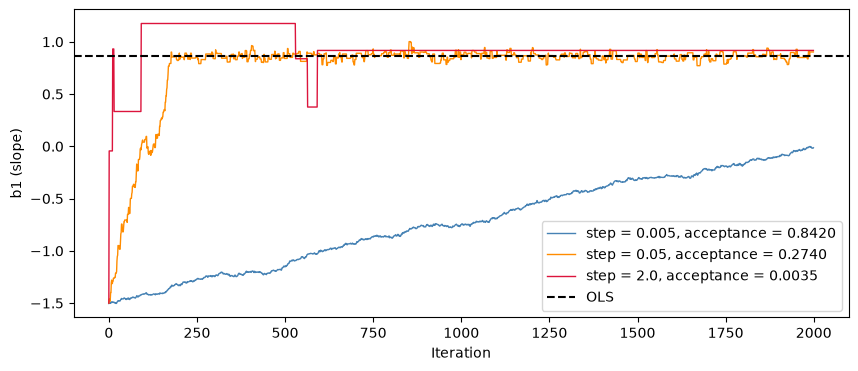

In [19]:
steps = [0.005, step , 2.0]                               # too small, good, too big
colors = ['steelblue', 'darkorange', 'crimson']

fig, ax = plt.subplots(figsize = (10, 4))
for s, c in zip(steps, colors):
    np.random.seed(seed)                                # same random numbers for a fair comparison
    ch, acc, _ = metropolis(sX, sY, beta_start, s, 2000)       # same start for all three
    ax.plot(ch[:, 0], color = c, lw = 1,
            label = f'step = {s}, acceptance = {acc.mean():.4f}')
ax.axhline(b1_ols, color = 'black', ls = '--', label = 'OLS')
ax.set_xlabel('Iteration'); ax.set_ylabel('b1 (slope)')
ax.legend(); plt.show()

### 7. Experiment 2: When does the prior matter?

Here we ask: how much can the prior change the answer? We compare a weak prior with a deliberately wrong and confident one, b1 ~ N(0.3, 0.1), using all 200 wells and a random 10:

* intuition - for a normal prior and a normal likelihood, the posterior mean is a weighted average of the prior mean and the data estimate, where each is weighted by its precision τ (1 / variance):
$$\text{posterior mean} \approx \frac{\tau_{prior}\,\mu_{prior} + \tau_{data}\,\hat b_{OLS}}{\tau_{prior} + \tau_{data}}$$

* the data precision grows with the number of wells, $\tau_{data} \approx n / \sigma^2$:
200 wells - τ_data ≈ 200 / 0.257 ≈ 780, while τ_prior = 1 / 0.1² = 100, so the posterior mean ≈ (100 · 0.3 + 780 · 0.862) / 880 ≈ 0.80, exactly what the experiment shows: the data win
10 wells - the data precision is about 20 times smaller, so the prior pulls the answer much more (0.42) and the posterior is wider: the prior wins.
  
**Conclusion** - priors matter most when data are scarce (e.g., new fields, few wells), so then the prior should come from real knowledge, such as analog fields, not be chosen arbitrarily

In [20]:
np.random.seed(seed)
idx10 = np.random.choice(len(sX), size = 10, replace = False)    # 10 random wells (no repeats)
sX10 = sX[idx10]; sY10 = sY[idx10]                               # the small dataset

weak   = (0.0, 1.0)                                              # prior for b1: N(0, 1), wide, "I don't know much"
strong = (0.3, 0.1)                                              # prior for b1: N(0.3, 0.1), narrow and wrong on purpose

cases = {                                                        # name -> (x, y, prior)
    '200 wells, weak prior':   (sX,   sY,   weak),
    '200 wells, strong prior': (sX,   sY,   strong),
    '10 wells, weak prior':    (sX10, sY10, weak),
    '10 wells, strong prior':  (sX10, sY10, strong),
}

b1_samples = {}                                                  # name -> b1 samples after burn-in
for name, (x, y, (m, s)) in cases.items():
    np.random.seed(seed)
    ch, acc, _ = metropolis(x, y, beta_start, step, n_iter, b1_mean = m, b1_sd = s)
    b1_samples[name] = ch[burn:, 0]
    p10, p50, p90 = np.percentile(b1_samples[name], [10, 50, 90])
    print(f'{name:25s}: b1 P10 = {p10:.2f}  P50 = {p50:.2f}  P90 = {p90:.2f}')

200 wells, weak prior    : b1 P10 = 0.81  P50 = 0.86  P90 = 0.91
200 wells, strong prior  : b1 P10 = 0.75  P50 = 0.80  P90 = 0.84
10 wells, weak prior     : b1 P10 = 0.70  P50 = 0.86  P90 = 1.01
10 wells, strong prior   : b1 P10 = 0.29  P50 = 0.42  P90 = 0.56


Posterior of b1 for each case, compared with the strong prior and OLS.

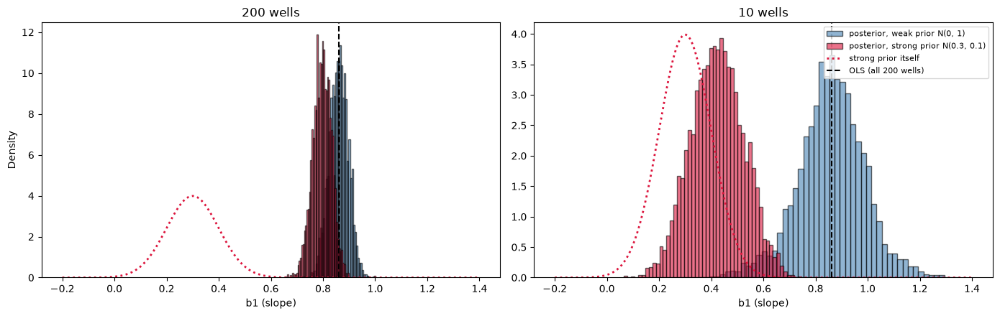

In [21]:
fig, axes = plt.subplots(1, 2, figsize = (14, 4.5), sharex = True)
b1_grid = np.linspace(-0.2, 1.4, 300)                            # b1 values for drawing the prior curve
panels = [('200 wells', axes[0]), ('10 wells', axes[1])]

for n_wells, ax in panels:
    ax.hist(b1_samples[f'{n_wells}, weak prior'], bins = 50, density = True, alpha = 0.6,
            color = 'steelblue', edgecolor = 'black', label = 'posterior, weak prior N(0, 1)')
    ax.hist(b1_samples[f'{n_wells}, strong prior'], bins = 50, density = True, alpha = 0.6,
            color = 'crimson', edgecolor = 'black', label = 'posterior, strong prior N(0.3, 0.1)')
    ax.plot(b1_grid, st.norm.pdf(b1_grid, loc = strong[0], scale = strong[1]),
            color = 'crimson', ls = ':', lw = 2, label = 'strong prior itself')
    ax.axvline(b1_ols, color = 'black', ls = '--', label = 'OLS (all 200 wells)')
    ax.set_title(n_wells); ax.set_xlabel('b1 (slope)')
axes[0].set_ylabel('Density'); axes[1].legend(loc = 'upper right', fontsize = 8)
plt.tight_layout(); plt.show()

### 8. Hamiltonian Monte Carlo and NUTS

Metropolis-Hastings works, but it is slow. In this section, we build a smarter sampler, the idea behind the samplers used in practice:

* the problem with Metropolis-Hastings - its proposals are blind: it doesn't know which direction is "uphill", so most proposals are wasted, steps must stay small, and consecutive samples are very similar
* the idea of HMC - borrow physics:
   * flip the posterior upside down, so the potential energy U(β) = -log-posterior and high probability becomes a low valley
   * give the parameters a random momentum p ~ N(0, 1), with kinetic energy K(p) = ½ Σ p²
   * let a ball roll on this surface: it speeds up going down (toward high probability) and slows down going up, and after a while it is somewhere far away but still in a good region, which becomes the proposal
* total energy H = U + K is conserved in exact physics, so a perfectly simulated roll would always be accepted

MH is a blindfolded hiker: random steps, checked only afterwards, so many are rejected and steps must stay small!

#### Gradient

First, the ball needs to know the slope of the surface, i.e., the gradient of the log-posterior:

* we approximate it numerically: nudge one parameter up and down by a tiny h and see how much the log-posterior changes:
$$\frac{\partial f}{\partial \beta_k} \approx \frac{f(\beta + h\,e_k) - f(\beta - h\,e_k)}{2h}$$
* libraries like PyMC calculate the exact gradient automatically (automatic differentiation), which is faster and more accurate
* reading the output:
   * at the OLS point, the gradient for b0 and σ is ≈ 0 (the top of the hill is flat), and for b1 it is -0.86: that is the prior - gently pulling b1 toward 0, so the posterior peak is very slightly left of OLS
   * at the bad start, the gradient points uphill: increase b1 (+120), decrease b0 (-76), and increase σ (+102), because a terrible line is better explained by assuming more noise.

In [22]:
print(grad_log_posterior(np.array([b1_ols, b0_ols, std_ols]), sX, sY))   # top of the hill
print(grad_log_posterior(np.array(beta_start), sX, sY))                 # bad start

[-8.61909538e-01  1.42108547e-09  2.55795385e-07]
[119.59547695 -76.49999999 102.14321545]


#### Leapfrog

The ball's total energy should be (almost) conserved; the smaller the step, the smaller the change, and the acceptance probability is exp(−energy change). So we simulate the roll itself with the leapfrog method, in L small time steps of size ε:

1. half kick: p ← p + (ε/2) · gradient
2. drift: β ← β + ε · p
3. kick: p ← p + ε · gradient (steps 2 and 3 repeat L times)
4. final half kick
* leapfrog is used because it is reversible and volume-preserving, two properties that keep HMC mathematically correct, and it conserves energy very well.
* the test - after 20 steps the energy change is tiny (0.0004, 0.005, 0.045 for ε = 0.005, 0.01, 0.02); the acceptance probability is min(1, exp(H_old - H_new)), i.e., 99.96%, 99.5% and 95.6%.

In [23]:
q0 = np.array([b1_ols, b0_ols, std_ols])
np.random.seed(seed); p0 = np.random.normal(size = 3)                 # random kick

for eps in [0.005, 0.01, 0.02]:
    q1, p1 = leapfrog(q0, p0, eps, 20, sX, sY)
    print('eps =', eps, ' energy change =', np.round(energy(q1, p1, sX, sY) - energy(q0, p0, sX, sY), 5))

eps = 0.005  energy change = 0.00042
eps = 0.01  energy change = 0.00457
eps = 0.02  energy change = 0.0446


#### HMC Sampler


Now we put the pieces together into the HMC sampler and start it from the same bad point as Metropolis-Hastings:

* each iteration: (1) random kick p, (2) roll with leapfrog, (3) accept with probability min(1, exp(H_old - H_new)), otherwise stay and record a repeat
* it is the same accept/reject logic as Metropolis-Hastings, but with energy instead of only the posterior ratio
* result - about 98% acceptance, and the chain reaches the posterior in about 5 iterations instead of about 200
* price - each iteration needs L gradient evaluations, so one HMC iteration costs much more than one Metropolis-Hastings iteration

In [24]:
np.random.seed(seed)
chain_hmc, acc_hmc = hmc(sX, sY, beta_start, 0.01, 20, 1000)
print('HMC acceptance rate:', np.round(acc_hmc.mean(), 3))
print('first 5 b1 values:', np.round(chain_hmc[:5, 0], 2))

HMC acceptance rate: 0.977
first 5 b1 values: [0.13 0.62 0.62 0.62 0.94]


#### Autocorrelation

Next, we check how independent the samples are, because acceptance alone does not tell the whole story:

* autocorrelation at lag k - the correlation between the chain and itself shifted by k iterations: 1 = a copy, 0 = independent
* Metropolis-Hastings - decays slowly (about 15 iterations to "forget"), so each sample adds little new information
* HMC (L = 10) - drops immediately and zigzags (negative values): each roll carries the ball to the other side of the valley, which is very efficient exploration
* HMC (L = 20) - is worse: the ball rolls across and back, makes a U-turn, and ends near where it started, so the work is wasted

**Conclusion** - HMC's trajectory length must be tuned, and the best L is different for every parameter and every problem

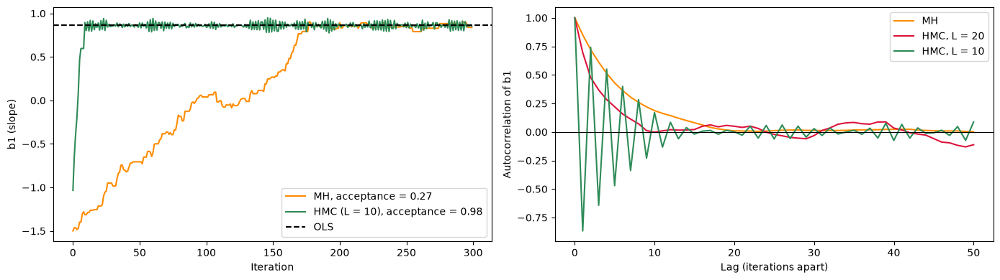

In [25]:
np.random.seed(seed)
chain_hmc10, acc_hmc10 = hmc(sX, sY, beta_start, 0.01, 10, 1000)        # shorter trajectory, L = 10

fig, axes = plt.subplots(1, 2, figsize = (14, 4))

# left: traces of b1, first 300 iterations
axes[0].plot(chain[:300, 0], color = 'darkorange', label = f'MH, acceptance = {accepted.mean():.2f}')
axes[0].plot(chain_hmc10[:300, 0], color = 'seagreen', label = f'HMC (L = 10), acceptance = {acc_hmc10.mean():.2f}')
axes[0].axhline(b1_ols, color = 'black', ls = '--', label = 'OLS')
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('b1 (slope)'); axes[0].legend()

# right: autocorrelation of b1 after burn-in
axes[1].plot(autocorr(chain[burn:, 0], 50), color = 'darkorange', label = 'MH')
axes[1].plot(autocorr(chain_hmc[100:, 0], 50), color = 'crimson', label = 'HMC, L = 20')
axes[1].plot(autocorr(chain_hmc10[100:, 0], 50), color = 'seagreen', label = 'HMC, L = 10')
axes[1].axhline(0, color = 'black', lw = 0.8)
axes[1].set_xlabel('Lag (iterations apart)'); axes[1].set_ylabel('Autocorrelation of b1'); axes[1].legend()
plt.tight_layout(); plt.show()

#### NUTS with PyMC

This leads us to NUTS, which solves the tuning problem automatically; here we run it with PyMC on the same model:

* NUTS (No-U-Turn Sampler) is HMC that stops the trajectory automatically when it starts to turn back, so there is no L to choose
* during the tuning (warm-up) phase it also adapts:
   * the step size ε, to reach a target acceptance (0.8 by default in PyMC)
   * a "mass matrix" that rescales each parameter by its own width, an automatic version of what we did by hand with standardization
* NUTS is the default sampler in [PyMC](https://www.pymc.io) and Stan, the tools used in research and industry; [ArviZ](https://python.arviz.org) is used for summaries. 

In [26]:
idata = nuts(sX, sY, seed)
az.summary(idata)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
b1,0.8609,0.037,0.8,0.92,5954,2956,1.00,0.00048,0.00067
b0,0.0002,0.037,-0.058,0.059,6196,3163,1.00,0.00047,0.0006
sigma,0.5131,0.0265,0.47,0.56,5627,3147,1.00,0.00036,0.00045


#### Comparison

Finally, we compare all three samplers side by side:

* effective sample size - how many independent samples a correlated chain is worth, where ρ_k is the autocorrelation at lag k:
$$ESS = \frac{N}{1 + 2\sum_{k \ge 1} \rho_k}$$
* Metropolis-Hastings: 9500 samples are worth about 830; HMC: 900 are worth about 2700; NUTS: 4000 are worth about 5900 (ESS can exceed N when the autocorrelation is negative)
* all three give the same posterior of b1; the difference is efficiency, not the answer.

In [27]:
post_mh   = chain[burn:]                                         # MH after burn-in
post_hmc  = chain_hmc10[100:]                                    # HMC (L = 10) after a short burn-in
post_nuts = idata.posterior['b1'].values.flatten()               # NUTS samples of b1 (4 chains joined)

table = pd.DataFrame({
    'method':       ['Metropolis-Hastings', 'HMC (L = 10)', 'NUTS (PyMC)'],
    'samples kept': [len(post_mh), len(post_hmc), len(post_nuts)],
    'acceptance':   [accepted.mean(), acc_hmc10.mean(), idata.sample_stats['acceptance_rate'].values.mean()],
    'b1 mean':      [post_mh[:, 0].mean(), post_hmc[:, 0].mean(), post_nuts.mean()],
    'ESS of b1':    [ess(post_mh[:, 0]), ess(post_hmc[:, 0]), ess(post_nuts)],
})
table.round(3)

,method,samples kept,acceptance,b1 mean,ESS of b1
0,Metropolis-Hastings,9500,0.268,0.860,829.458
1,HMC (L = 10),900,0.983,0.861,2658.818
2,NUTS (PyMC),4000,0.824,0.861,5869.190


All three samplers give the same posterior of b1.

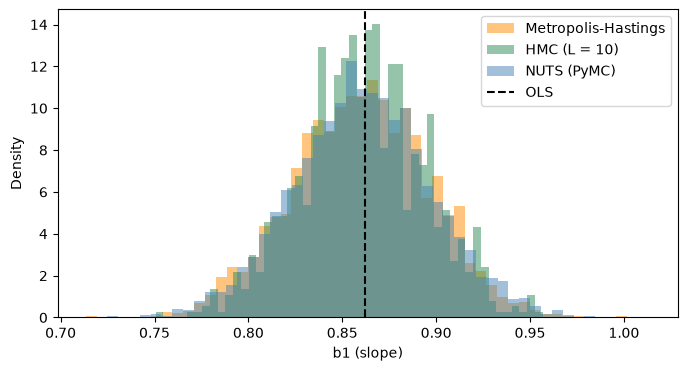

In [28]:
plt.figure(figsize = (8, 4))
plt.hist(post_mh[:, 0],   bins = 50, density = True, alpha = 0.5, color = 'darkorange', label = 'Metropolis-Hastings')
plt.hist(post_hmc[:, 0],  bins = 50, density = True, alpha = 0.5, color = 'seagreen',   label = 'HMC (L = 10)')
plt.hist(post_nuts, bins = 50, density = True, alpha = 0.5, color = 'steelblue',  label = 'NUTS (PyMC)')
plt.axvline(b1_ols, color = 'black', ls = '--', label = 'OLS')
plt.xlabel('b1 (slope)'); plt.ylabel('Density'); plt.legend(); plt.show()

### 9. Synthetic Example: When Metropolis–Hastings Gets Stuck

So far, the posterior was a round hill and every sampler eventually found the answer. Here we make the problem harder on purpose and see who copes:

* why synthetic data - the true answer is known (slope 0.5, intercept 1), so we can check every sampler against it
* why the posterior becomes a narrow valley - the porosity is not standardized and sits far from 0 (10-20 %); the intercept is the value at x = 0, so tilting the line slightly steeper forces the intercept down a lot to keep the line through the data, which makes slope and intercept strongly negatively correlated:
$$\text{corr}(b_1, b_0) \approx -\frac{\bar x}{\sqrt{\bar x^2 + s_x^2}} \approx -\frac{15}{\sqrt{15^2 + 2.9^2}} \approx -0.98$$
* why Metropolis-Hastings gets stuck - its step must be small enough to fit the narrow width of the valley, but then it needs a huge number of random steps to travel along its long direction: 8000 samples are worth only about 5 independent ones
* why HMC is better - the gradient guides the ball along the valley, so one trajectory travels far; it is about 40 times more efficient, but still sensitive to ε and L (with slightly larger values, the acceptance collapsed)
* why NUTS is the best - automatic trajectory length, plus adapted step size and scaling

**Conclusion** - standardizing the inputs is not cosmetic: it makes the posterior round and easy to sample, and in real models with many correlated parameters, gradient-based samplers like NUTS are essential.

In [29]:
rng = np.random.default_rng(seed)                       # random generator for the synthetic data
n_syn = 50                                              # number of synthetic wells
x_syn = rng.uniform(10, 20, n_syn)                      # porosity, NOT standardized
y_syn = 0.5 * x_syn + 1 + rng.normal(0, 1, n_syn)       # true line: slope 0.5, intercept 1, noise sd 1
start_syn = [0.0, 0.0, 2.0]                             # same bad start for all samplers

Run MH, HMC and NUTS on the synthetic data.

In [30]:
np.random.seed(seed)
ch_mh_syn, acc_mh_syn, _ = metropolis(x_syn, y_syn, start_syn, 0.05, 10000)    # MH
np.random.seed(seed)
ch_hmc_syn, acc_hmc_syn = hmc(x_syn, y_syn, start_syn, 0.01, 50, 1000)         # HMC
idata_syn = nuts(x_syn, y_syn, seed)                                           # NUTS

syn = {'Metropolis-Hastings': (ch_mh_syn[2000:, 0], ch_mh_syn[2000:, 1]),
       'HMC (eps = 0.01, L = 50)': (ch_hmc_syn[200:, 0], ch_hmc_syn[200:, 1]),
       'NUTS (PyMC)': (idata_syn.posterior['b1'].values.flatten(), idata_syn.posterior['b0'].values.flatten())}

pd.DataFrame({'method': list(syn),
              'samples kept': [len(v[0]) for v in syn.values()],
              'ESS of b1': [ess(v[0]) for v in syn.values()],
              'ESS of b0': [ess(v[1]) for v in syn.values()]}).round(0)

,method,samples kept,ESS of b1,ESS of b0
0,Metropolis-Hastings,8000,5.0,4.0
1,"HMC (eps = 0.01, L = 50)",800,192.0,190.0
2,NUTS (PyMC),4000,1463.0,1459.0


The first 300 iterations of each sampler on the posterior valley (σ fixed at 1 for the background map); the black star is the true answer.

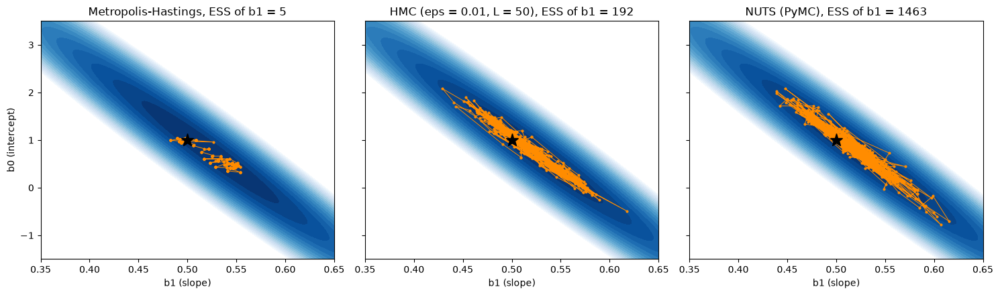

In [31]:
b1_g = np.linspace(0.35, 0.65, 120); b0_g = np.linspace(-1.5, 3.5, 120)          # grid over the valley
lp_g = np.array([[log_posterior([b1, b0, 1.0], x_syn, y_syn) for b1 in b1_g] for b0 in b0_g])

fig, axes = plt.subplots(1, 3, figsize = (15, 4.5), sharex = True, sharey = True)
for ax, (name, (s1, s0)) in zip(axes, syn.items()):
    ax.contourf(b1_g, b0_g, lp_g, levels = np.linspace(lp_g.max() - 30, lp_g.max(), 20), cmap = 'Blues')
    ax.plot(s1[:300], s0[:300], '-o', color = 'darkorange', ms = 2, lw = 0.7)       # path of 300 iterations
    ax.plot(0.5, 1, '*', color = 'black', ms = 14)
    ax.set_title(f'{name}, ESS of b1 = {ess(s1):.0f}'); ax.set_xlabel('b1 (slope)')
axes[0].set_ylabel('b0 (intercept)')
plt.tight_layout(); plt.show()

### Results


* **Metropolis–Hastings (MH) recovers the Ordinary Least Squares (OLS) answer, and adds uncertainty.** The slope b1 has a median (P50) of 0.86, the same as OLS, with an 80% interval (P10–P90) of 0.81–0.91. OLS gives only one number; MCMC gives a full distribution, so we also know how sure we can be.

* **In original units**, every additional 1% of porosity adds about 287 MCFPD of production (P10–P90: 271–303 MCFPD per %).

* **Step size controls how well the chain explores:**
    * too small (0.005): 84% of proposals are accepted, but the steps are tiny, and after 2000 iterations the chain still hasn't reached the answer
    * too big (2.0): only 0.35% are accepted, so the chain stays stuck at the same value for hundreds of iterations
    * good (0.05): 27% are accepted, and the chain reaches the answer in about 200 iterations, then explores around it

* **The prior matters only when data is scarce.** A deliberately wrong, confident prior, N(0.3, 0.1), moves the slope only from 0.86 to 0.80 with 200 wells, but pulls it down to 0.42 with 10 wells. With little data, the prior dominates; with a lot of data, the data wins.

* **HMC and NUTS give the same answer with more information per sample.** On the real data, MH's 9500 samples are worth about 830 independent ones, HMC's 900 about 2700, and NUTS's 4000 about 5900 (ESS of b1). HMC accepts about 98% of proposals, but its trajectory length must be tuned: too long and the ball makes a U-turn, which NUTS avoids automatically.

* **On a correlated posterior MH gets stuck.** Without standardization, slope and intercept form a narrow valley; MH's 8000 samples are worth only a handful of independent ones, HMC does much better, and NUTS still samples the valley well, which is why NUTS is the industry standard (and why we standardize).

### Parting Comments

* I am a PhD student in the Hildebrand Department of Petroleum and Geosystems Engineering at The University of Texas at Austin.
* Through this project I practiced Python data analysis with NumPy, pandas, matplotlib and scikit-learn, Bayesian sampling with PyMC, and learned to build educational animations with Manim.
* I am interested in machine learning for subsurface and uncertainty quantification, and I am looking for **internship and research** opportunities.
* Feel free to reach out on [LinkedIn](https://www.linkedin.com/in/anastasiia-khorkhorina/).

AI assistance (Claude) was used for tutoring, code review, and drafting parts of the HMC, NUTS and synthetic-example code.

#### About the Supervising Professor

Michael Pyrcz is a professor in the [Cockrell School of Engineering](https://cockrell.utexas.edu/faculty-directory/alphabetical/p), and the [Jackson School of Geosciences](https://www.jsg.utexas.edu/researcher/michael_pyrcz/), at [The University of Texas at Austin](https://www.utexas.edu/), where he researches and teaches subsurface, spatial data analytics, geostatistics, and machine learning. Michael is also,

* the principal investigator of the [Energy Analytics](https://fri.cns.utexas.edu/energy-analytics) freshmen research initiative and a core faculty in the Machine Learn Laboratory in the College of Natural Sciences, The University of Texas at Austin

* an associate editor for [Computers and Geosciences](https://www.sciencedirect.com/journal/computers-and-geosciences/about/editorial-board), and a board member for [Mathematical Geosciences](https://link.springer.com/journal/11004/editorial-board), the International Association for Mathematical Geosciences. 

Michael has written over 70 [peer-reviewed publications](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en), a [Python package](https://pypi.org/project/geostatspy/) for spatial data analytics, co-authored a textbook on spatial data analytics, [Geostatistical Reservoir Modeling](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) and author of two recently released e-books, [Applied Geostatistics in Python: a Hands-on Guide with GeostatsPy](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) and [Applied Machine Learning in Python: a Hands-on Guide with Code](https://geostatsguy.github.io/MachineLearningDemos_Book/intro.html).

All of Michael’s university lectures are available on his [YouTube Channel](https://www.youtube.com/@GeostatsGuyLectures) with links to 100s of Python interactive dashboards and well-documented workflows in over 40 repositories on his [GitHub account](https://github.com/GeostatsGuy), to support any interested students and working professionals with evergreen content. To find out more about Michael’s work and shared educational resources visit his [Website](www.michaelpyrcz.com).

#### Want to Work Together?

I hope this content is helpful to those that want to learn more about subsurface modeling, data analytics and machine learning. Students and working professionals are welcome to participate.

* Want to invite me to visit your company for training, mentoring, project review, workflow design and / or consulting? I'd be happy to drop by and work with you! 

* Interested in partnering, supporting my graduate student research or my Subsurface Data Analytics and Machine Learning consortium (co-PI is Professor John Foster)? My research combines data analytics, stochastic modeling and machine learning theory with practice to develop novel methods and workflows to add value. We are solving challenging subsurface problems!

* I can be reached at mpyrcz@austin.utexas.edu.

I'm always happy to discuss,

*Michael*

Michael Pyrcz, Ph.D., P.Eng. Professor, Cockrell School of Engineering and The Jackson School of Geosciences, The University of Texas at Austin

More Resources Available at: [Twitter](https://twitter.com/geostatsguy) | [GitHub](https://github.com/GeostatsGuy) | [Website](http://michaelpyrcz.com) | [GoogleScholar](https://scholar.google.com/citations?user=QVZ20eQAAAAJ&hl=en&oi=ao) | [Geostatistics Book](https://www.amazon.com/Geostatistical-Reservoir-Modeling-Michael-Pyrcz/dp/0199731446) | [YouTube](https://www.youtube.com/channel/UCLqEr-xV-ceHdXXXrTId5ig)  | [Applied Geostats in Python e-book](https://geostatsguy.github.io/GeostatsPyDemos_Book/intro.html) | [Applied Machine Learning in Python e-book](https://geostatsguy.github.io/MachineLearningDemos_Book/) | [LinkedIn](https://www.linkedin.com/in/michael-pyrcz-61a648a1)